# Notebook 10 – Target Variable Analysis

**Sprint 4 – Data Inspection & Exploratory Data Analysis**  
Workflow: `Load → Inspect → Understand → Analyze → Visualize → Identify Problems → Document Findings`  
**Dataset:** Telco Customer Churn (IBM sample data, 7,043 customers × 21 columns)

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# Load the RAW dataset (nothing has been modified yet)
PATH = "../data/telco.csv"
if not os.path.exists(PATH):   # fallback: download straight from the public source
    PATH = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df_raw = pd.read_csv(PATH)
df = df_raw.copy()
print("Loaded:", df.shape)

# NOTE: 'TotalCharges' is stored as text in the raw file (11 blank strings, see 03_Data_Quality).
# For ANALYSIS ONLY we create a numeric working copy; blanks become NaN. The raw file is untouched,
# and the formal treatment of these rows is deferred to the preprocessing sprint.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in df.columns if c not in num_cols + ["customerID"]]
target = "Churn"
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)   # helper for rates/correlations (analysis only)

Loaded: (7043, 21)


### Topic Explanation

This topic studies the outcome variable's type, distribution, class balance, and differences across important segments.

## Why analyse the target first?

The target defines the ML problem: its **type** (classification vs regression), **balance**, **noise** and **distribution** determine the model family, the loss function, the evaluation metric, the data split strategy and the baseline you must beat. A model built without understanding the target can look excellent (e.g. 73% accuracy by always predicting 'No') while being useless.

### Topic Explanation

This topic describes the shape of values, including symmetry, skewness, centre, spread, and tail behaviour.

## 1. Classification Target – Class Distribution, Counts, Percentages and Imbalance

### 1. Concept
For classification, check **class counts**, **percentages** and the **imbalance ratio** (majority / minority). Imbalance affects how metrics should be read (accuracy paradox).

### 2. Example
*Simple:* a fraud dataset with 1 fraud in 1,000 transactions.  
*Business:* about one in four telecom customers churns.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

In [2]:
counts = df["Churn"].value_counts()
pct = df["Churn"].value_counts(normalize=True) * 100
tab = pd.DataFrame({"count": counts, "percent": pct.round(2)})
display(tab)
print(f"Imbalance ratio (majority/minority): {counts.max()/counts.min():.2f} : 1")
print(f"Naive baseline accuracy (always predict 'No'): {counts.max()/counts.sum():.2%}")

,count,percent
Churn,,
No,5174,73.46
Yes,1869,26.54


Imbalance ratio (majority/minority): 2.77 : 1
Naive baseline accuracy (always predict 'No'): 73.46%


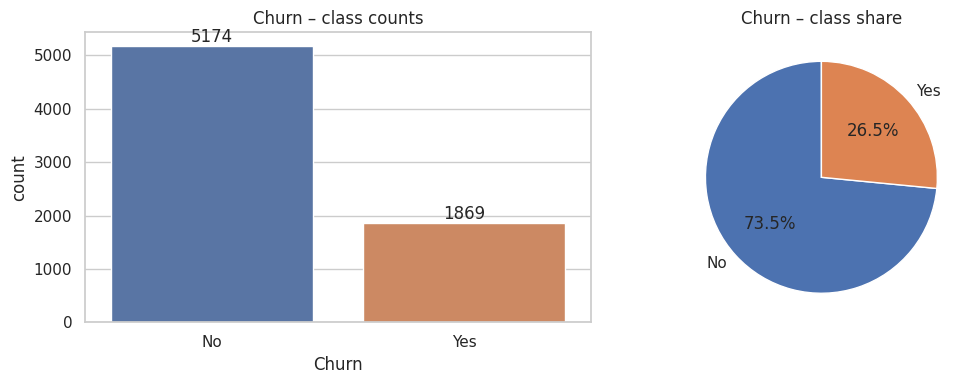

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="Churn", ax=axes[0], palette=["#4c72b0", "#dd8452"]); axes[0].set_title("Churn – class counts")
for p in axes[0].patches: axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom")
axes[1].pie(counts, labels=counts.index, autopct="%1.1f%%", colors=["#4c72b0", "#dd8452"], startangle=90); axes[1].set_title("Churn – class share")
plt.tight_layout(); plt.show()

### 5. Interpretation
5,174 customers (73.46%) stayed and 1,869 (26.54%) churned. The imbalance ratio is ≈ 2.77 : 1. A model that always predicts 'No' would be **73.5% accurate** while catching zero churners.

### 6. Insight
The imbalance is **moderate**, not extreme: a model can learn from the 1,869 positive examples, but the plain accuracy metric is inflated.

### 7. AI/ML Relevance
Use stratified train/test splits, evaluate with recall, precision, F1, ROC-AUC/PR-AUC, and consider class weights or resampling (SMOTE) in the modelling sprint. Any model must beat the 73.5% baseline and, more importantly, achieve useful recall on churners.

### Topic Explanation

This topic studies the outcome variable's type, distribution, class balance, and differences across important segments.

## 2. Target vs Key Segments

### 1. Concept
Understand how the target rate changes across the most important segments to see whether it is stable and meaningful.

### 2. Example
Business: churn rate of the whole base vs its biggest risk groups.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

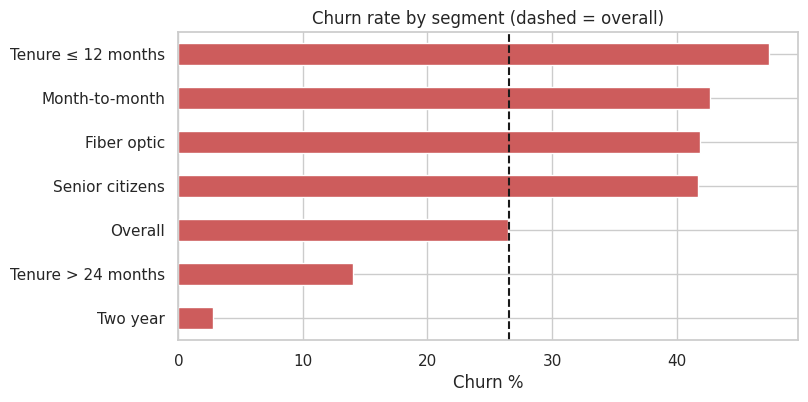

,churn_%
Two year,2.8
Tenure > 24 months,14.0
Overall,26.5
Senior citizens,41.7
Fiber optic,41.9
Month-to-month,42.7
Tenure ≤ 12 months,47.4


In [4]:
overall = df.ChurnFlag.mean() * 100
seg = {
    "Overall": df.ChurnFlag.mean(),
    "Month-to-month": df.loc[df.Contract == "Month-to-month", "ChurnFlag"].mean(),
    "Two year": df.loc[df.Contract == "Two year", "ChurnFlag"].mean(),
    "Tenure ≤ 12 months": df.loc[df.tenure <= 12, "ChurnFlag"].mean(),
    "Tenure > 24 months": df.loc[df.tenure > 24, "ChurnFlag"].mean(),
    "Fiber optic": df.loc[df.InternetService == "Fiber optic", "ChurnFlag"].mean(),
    "Senior citizens": df.loc[df.SeniorCitizen == 1, "ChurnFlag"].mean(),
}
seg = pd.Series(seg).mul(100).round(1).sort_values()
ax = seg.plot(kind="barh", figsize=(8, 4), color="indianred"); ax.axvline(overall, color="k", ls="--")
ax.set_xlabel("Churn %"); ax.set_title("Churn rate by segment (dashed = overall)"); plt.show()
seg.to_frame("churn_%")

### 5. Interpretation
Churn ranges from 2.8% (two-year contracts) to ≈ 47% for tenure ≤ 12 months and ≈ 43% for month-to-month contracts, versus the overall 26.5%.

### 6. Insight
The target is highly segment-dependent; early-tenure and flexible-contract customers are the main source of churn.

### 7. AI/ML Relevance
Strong, non-uniform signal across segments indicates the problem is learnable; it also warns that evaluation should check performance *within* segments.

### Topic Explanation

This topic studies the outcome variable's type, distribution, class balance, and differences across important segments.

## 3. Regression Target (illustration): MonthlyCharges as an alternative target

### 1. Concept
If the business question changed to *predict the monthly bill*, the target would be numeric. Analyse it with mean, median, variance, standard deviation, skewness and outliers. (No regression is built – this only shows the analysis required.)

### 2. Example
Business: forecast revenue per customer.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

,MonthlyCharges
mean,64.76
median,70.35
variance,905.41
std,30.09
min,18.25
max,118.75
skewness,-0.22
kurtosis,-1.26
IQR outliers,0.00


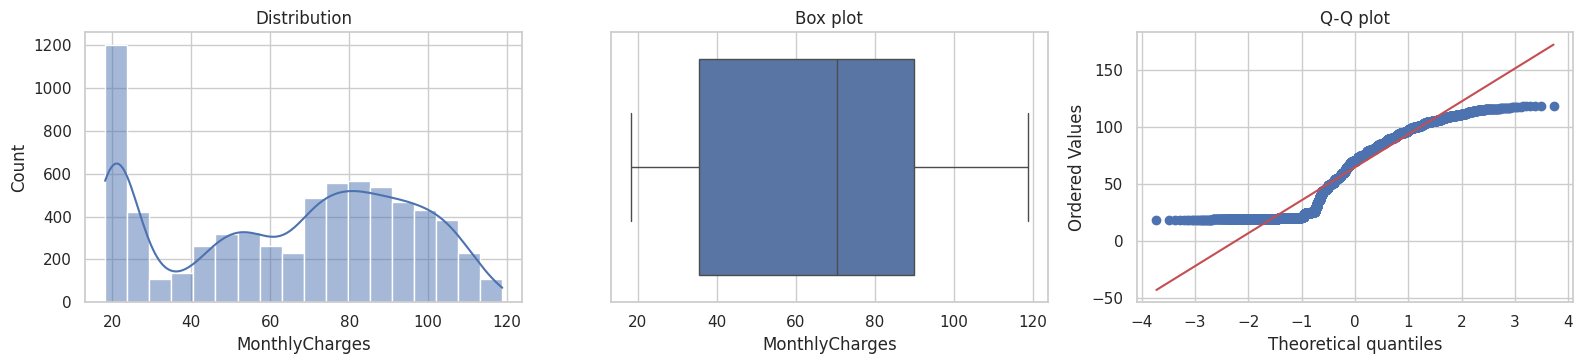

In [5]:
t = df["MonthlyCharges"]
q1, q3 = t.quantile([.25, .75]); iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
summary = pd.Series({
    "mean": t.mean(), "median": t.median(), "variance": t.var(), "std": t.std(),
    "min": t.min(), "max": t.max(), "skewness": t.skew(), "kurtosis": t.kurt(),
    "IQR outliers": int(((t < lo) | (t > hi)).sum()),
}).round(2)
display(summary.to_frame("MonthlyCharges"))
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
sns.histplot(t, kde=True, ax=axes[0]).set_title("Distribution")
sns.boxplot(x=t, ax=axes[1]).set_title("Box plot")
stats.probplot(t, plot=axes[2]); axes[2].set_title("Q-Q plot")
plt.tight_layout(); plt.show()

### 5. Interpretation
Mean ≈ 64.8, median ≈ 70.4, std ≈ 30.1 (variance ≈ 905), skewness ≈ –0.22, no IQR outliers. The distribution is *bimodal*, not normal.

### 6. Insight
A regression target that is bimodal means one global model would fit both clusters poorly; a segment feature (internet vs no internet) or a mixture/tree model would be needed.

### 7. AI/ML Relevance
For regression the target's skew/outliers determine whether to transform it (log) and which loss (MSE vs MAE/Huber) to use.

### Topic Explanation

This topic studies the outcome variable's type, distribution, class balance, and differences across important segments.

## Why Target Understanding Matters Before ML

1. **Problem framing** – classification vs regression, binary vs multi-class.
2. **Metric choice** – imbalance makes accuracy misleading; use recall/precision/F1/PR-AUC.
3. **Splitting strategy** – stratified sampling to preserve the 26.5% churn rate in train and test.
4. **Baseline** – the 73.5% majority-class accuracy is the number to beat.
5. **Leakage detection** – any feature derived from the outcome (here none) must be excluded.
6. **Business alignment** – churn costs money: ~\$139k of monthly recurring revenue belongs to churned customers (computed in Notebook 12).